In [26]:
import pandas as pd

In [27]:
subscribers = pd.read_csv(r"C:\Users\daran\Downloads\ff5a102e4361911d42cef9e21cda23d0\subscribers_clean.csv", parse_dates=["signup_date", "churn_date"])
titles      = pd.read_csv(r"C:\Users\daran\Downloads\ff5a102e4361911d42cef9e21cda23d0\titles_clean.csv",      parse_dates=["date_added", "license_expiry"])
watch       = pd.read_csv(r"C:\Users\daran\Downloads\ff5a102e4361911d42cef9e21cda23d0\watch_history_clean.csv", parse_dates=["watch_date"])
watchlist   = pd.read_csv(r"C:\Users\daran\Downloads\ff5a102e4361911d42cef9e21cda23d0\watchlist_clean.csv",   parse_dates=["added_date"])

In [28]:
print(subscribers.shape,titles.shape,watch.shape,watchlist.shape)

(15000, 15) (9000, 23) (650000, 11) (64939, 6)


### KPI 1: Total Watch Hours

In [29]:
total_hours = watch["watch_duration_min"].sum() / 60
print(f"Total watch hours: {total_hours:,.0f}")  
print(f"Excluding after-churn sessions: {watch.loc[~watch['after_churn'], 'watch_duration_min'].sum() / 60:,.0f}") 

Total watch hours: 3,333,468
Excluding after-churn sessions: 2,660,892


**Total Watch Hours:** Total watch time is 3,333,468 hours (3.33 million) across all 650,000 viewing sessions, calculated as the sum of watch_duration_min divided by 60. It measures the overall size of the platform's engagement, about 222 hours per subscriber on the 15,000-subscriber base, and it is heavily recent: the first five months of 2026 alone account for about two thirds of it. The figure counts every session, including 131,199 sessions (20.2% of hours) dated after the subscriber's churn date; without them the total is 2,660,892 hours.

### KPI 2 : Active Rate

In [30]:
active = subscribers["is_active"].sum()
active_rate = active / len(subscribers) * 100
print(active, f"{active_rate:.1f}%")     

11199 74.7%


**Active Rate:** 74.7% of subscribers are active (11,199 of 15,000), calculated as active subscribers divided by all subscribers. It measures the health of the subscriber base, and it is above the PRD's 70% target, so the target is met, although only by about four points. The rate hides differences between plans: 81.9% of Premium and 75.9% of Standard subscribers are still active, against 65.7% of Basic with Ads.

### KPI 3: Churn Rate

In [31]:
churn_rate = (~subscribers["is_active"]).mean() * 100
print(f"{churn_rate:.1f}%")            
print(round(active_rate + churn_rate, 1))           

25.3%
100.0


In [32]:
plan = subscribers.groupby("plan_type")["is_active"].agg(["sum", "count"])
plan["active_rate_%"] = (plan["sum"] / plan["count"] * 100).round(1)
plan["churn_rate_%"] = (100 - plan["active_rate_%"]).round(1)
print(plan)     

                 sum  count  active_rate_%  churn_rate_%
plan_type                                               
Basic with Ads  2929   4458           65.7          34.3
Premium         3639   4442           81.9          18.1
Standard        4631   6100           75.9          24.1


**Churn Rate:** 25.3% of subscribers have left (3,801 of 15,000), calculated as inactive subscribers divided by all subscribers, and it is the mirror image of the active rate (the two add up to 100.0%). It is below the PRD's 30% ceiling, so the target is met, but one subscriber in four is lost revenue. Basic with Ads is the weak spot at 34.3%, above the ceiling on its own, against 24.1% for Standard and 18.1% for Premium.

### KPI 4: Average Completion Rate

In [33]:
avg_completion = watch["completion_pct"].mean()
print(f"{avg_completion:.1f}%")                      

65.3%


**Average Completion Rate:** On average, viewers watch 65.3% of a title in a session, calculated as the mean of completion_pct over all 650,000 sessions. It is above the PRD's 60% target, so the target is met, but only about 15% of sessions reach the 90% mark used for the completed flag, so most viewing stops before the end. The figure is the same with or without the sessions dated after churn, and it varies very little by genre (64.7% to 66.8%).

### KPI 5: Monthly Recurring Revenue

In [34]:
active_subs = subscribers[subscribers["is_active"]]
mrr = active_subs["monthly_price_usd"].sum()
print(f"MRR: ${mrr:,.2f}")      

MRR: $175,868.51


In [35]:
rev = active_subs.groupby("plan_type")["monthly_price_usd"].agg(["count", "sum"])
rev["share_of_mrr_%"] = (rev["sum"] / rev["sum"].sum() * 100).round(1)
print(rev)      

                count       sum  share_of_mrr_%
plan_type                                      
Basic with Ads   2929  20473.71            11.6
Premium          3639  83660.61            47.6
Standard         4631  71734.19            40.8


**Monthly Recurring Revenue (MRR):** Monthly recurring revenue is $175,868.51 from the 11,199 active subscribers, calculated as the sum of monthly_price_usd for active subscribers only, which is about $2.11 million a year at the current rate. It measures the money the platform actually earns each month. Premium brings in the most ($83,660.61, 47.6% of MRR) from only 32.5% of active subscribers, followed by Standard ($71,734.19, 40.8%), while Basic with Ads contributes just $20,473.71 (11.6%) despite 26.2% of active subscribers.

### KPI 6: ARPU

In [36]:
arpu = mrr / len(active_subs)
print(f"ARPU: ${arpu:,.2f}")     

ARPU: $15.70


**ARPU:** Average revenue per active subscriber is $15.70 per month, calculated as MRR divided by the 11,199 active subscribers. It sits between the Standard price ($15.49) and Premium ($22.99), pulled up by the large Premium and Standard base and down by the $6.99 Basic with Ads plan. Any move of subscribers from Basic with Ads to a paid plan raises it directly, which makes the plan mix the main lever on this number.


### KPI 7: Average Watch Time per Subscriber

In [37]:
print(round(total_hours / len(active_subs), 1))              
active_hours = watch.loc[watch["subscriber_id"].isin(active_subs["subscriber_id"]), "watch_duration_min"].sum() / 60
print(round(active_hours / len(active_subs), 1))            

297.7
223.4


In [38]:
kpi7_prd     = total_hours / len(active_subs)        # PRD formula: all hours / active subscribers
kpi7_matched = active_hours / len(active_subs)       # active subscribers' own hours / active subscribers

**Average Watch Time per Subscriber:** By the PRD formula (total watch hours divided by active subscribers), the figure is 297.7 hours, but this overstates it, because the 3,333,468 hours in the numerator include sessions from subscribers who have since churned, while the denominator counts only active ones. Dividing only the active subscribers' own hours by the 11,199 active subscribers gives 223.4 hours, which is the like-for-like figure and the one to rely on; it is close to the all-subscriber average of about 222 hours, so active and churned subscribers watch at a similar level. This matched figure is also not affected by the sessions dated after churn, since active subscribers have no churn date.

### KPI 8: Watchlist Conversion

In [39]:
conv = watchlist["watched"].mean() * 100
print(watchlist["watched"].sum(), len(watchlist), f"{conv:.1f}%")   

30020 64939 46.2%


**Watchlist Conversion:** 46.2% of watchlist entries were watched (30,020 of 64,939), calculated as watched entries divided by all entries on the cleaned watchlist. It measures how often a subscriber's intent to watch becomes viewing, and it is above the PRD's 40% target, so the target is met; the result is the same on the raw table (30,048 of 65,000, also 46.2%), so removing the 61 duplicate entries did not change it. The figure rests on the watched flag as recorded: 29,577 of the 30,020 watched entries have no matching session in the viewing history, so the flag cannot be confirmed from the other tables.

### KPI 9: Hit Concentration

In [40]:
plays = watch.groupby("title_id").size().reindex(titles["title_id"]).fillna(0).sort_values(ascending=False)
top_n = int(len(titles) * 0.10)               
hit_conc = plays.head(top_n).sum() / plays.sum() * 100
print(top_n, f"{hit_conc:.1f}%")                            

900 31.0%


In [41]:
print((plays > 0).sum())          
hours = watch.groupby("title_id")["watch_duration_min"].sum().reindex(titles["title_id"]).fillna(0).sort_values(ascending=False)
print(f"{hours.head(top_n).sum() / hours.sum() * 100:.1f}%")  

9000
50.7%


**Hit Concentration:** The top 10% of titles (900 of 9,000) account for 31.0% of all plays, calculated as plays from those 900 most-played titles divided by total plays, where a play is one viewing session (650,000 in all). That is about three times their share of the catalogue, so a set of hits does carry a disproportionate share of viewing, but the concentration is moderate and not extreme: the other 8,100 titles still deliver 69% of plays, and every one of the 9,000 titles has at least one session. The risk of depending on a few titles is therefore limited, though it is higher when measured in watch hours (about 51% for the top 10%), because long TV titles dominate that measure.

### KPI 10: Originals Share of Hours

In [42]:
w = watch.merge(titles[["title_id", "is_original"]], on="title_id", how="left")
orig_share = w.loc[w["is_original"], "watch_duration_min"].sum() / w["watch_duration_min"].sum() * 100
print(len(w), f"{orig_share:.1f}%") 

650000 27.2%


In [43]:
orig = w.groupby("is_original")["watch_duration_min"].sum() / 60
n_titles = titles["is_original"].value_counts()
print((orig / n_titles).round(0))          
print(round(titles["is_original"].mean() * 100, 1))   

is_original
False    345.0
True     461.0
dtype: float64
21.8


**Originals Share of Hours:** Originals account for 27.2% of all watch hours (about 905,700 of 3,333,468), calculated as hours on titles flagged is_original divided by total hours. They are only 21.8% of the catalogue (1,966 of 9,000 titles), so each Original earns about 461 hours against 345 for a licensed title, roughly a third more, which means the Originals are carrying more than their weight. This is the figure to watch when judging whether production spending is justified, though it is only a share of viewing and says nothing about what the Originals cost compared with the licences.

### Cohort Retention Analysis

A subscriber is retained at N months if churn_date is blank or later than signup + N months; cohorts whose checkpoint falls after 2026-05-31 are left blank.

Viewing dates were not used because 131,199 sessions are dated after churn (see Phase 1)

In [44]:
DATA_END = pd.Timestamp("2026-05-31")
sub = subscribers[["subscriber_id", "signup_date", "churn_date", "plan_type"]].copy()
sub["cohort"] = sub["signup_date"].dt.to_period("M")

for n in (3, 6, 12):
    checkpoint = sub["signup_date"] + pd.DateOffset(months=n)
    eligible   = checkpoint <= DATA_END
    retained   = sub["churn_date"].isna() | (sub["churn_date"] > checkpoint)
    sub[f"ret_{n}m"] = retained.astype(float).where(eligible)    

print(sub[["ret_3m", "ret_6m", "ret_12m"]].notna().sum())       
print((sub[["ret_3m", "ret_6m", "ret_12m"]].mean() * 100).round(1))   

ret_3m     14353
ret_6m     13724
ret_12m    12441
dtype: int64
ret_3m     97.7
ret_6m     95.3
ret_12m    92.2
dtype: float64


In [45]:
cohort = sub.groupby("cohort").agg(size=("subscriber_id", "size"),
                                   r3=("ret_3m", "mean"), r6=("ret_6m", "mean"), r12=("ret_12m", "mean"))
cohort[["r3", "r6", "r12"]] = (cohort[["r3", "r6", "r12"]] * 100).round(1)
print(len(cohort), cohort["size"].min(), int(cohort["size"].median()), cohort["size"].max())  
print(cohort.tail(8))

125 4 121 232
         size    r3    r6  r12
cohort                        
2025-10   198  90.4  75.8  NaN
2025-11   225  90.2  81.3  NaN
2025-12   217  90.3   NaN  NaN
2026-01   232  88.8   NaN  NaN
2026-02   180  86.1   NaN  NaN
2026-03   214   NaN   NaN  NaN
2026-04   210   NaN   NaN  NaN
2026-05   223   NaN   NaN  NaN


In [46]:
sub["cohort_year"] = sub["signup_date"].dt.year
by_year = (sub.groupby("cohort_year")[["ret_3m", "ret_6m", "ret_12m"]].mean() * 100).round(1)
by_year.columns = ["3 months", "6 months", "12 months"]
print(by_year)

             3 months  6 months  12 months
cohort_year                               
2016             98.7      97.9       96.2
2017             99.5      98.8       97.2
2018             99.0      98.3       96.1
2019             99.0      97.8       95.8
2020             98.9      97.6       95.3
2021             99.0      97.0       94.3
2022             98.3      96.7       93.6
2023             98.8      96.2       91.0
2024             98.0      94.7       88.7
2025             94.6      87.7       80.4
2026             87.6       NaN        NaN


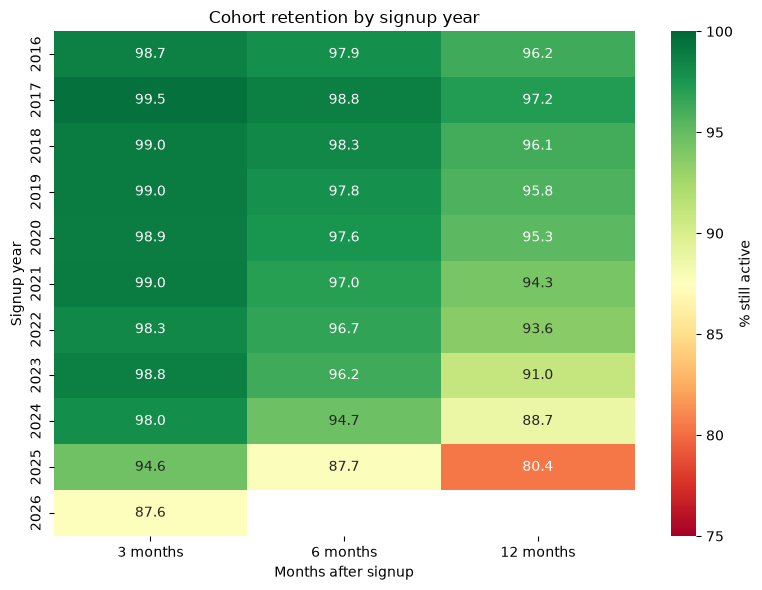

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(by_year, annot=True, fmt=".1f", cmap="RdYlGn", vmin=75, vmax=100,
            cbar_kws={"label": "% still active"}, ax=ax)
ax.set_title("Cohort retention by signup year")
ax.set_xlabel("Months after signup"); ax.set_ylabel("Signup year")
plt.tight_layout()
plt.savefig("charts/bonus_cohort_retention.png", dpi=150, bbox_inches="tight")
plt.show()

In [48]:
rows = {}
for n in (3, 6, 12):
    rows[f"{n} months"] = (sub.groupby("plan_type")[f"ret_{n}m"].mean() * 100).round(1)
by_plan = pd.DataFrame(rows)
print(by_plan)       

                3 months  6 months  12 months
plan_type                                    
Basic with Ads      96.9      93.7       88.9
Premium             98.4      96.8       94.5
Standard            97.6      95.3       92.8


**Cohort retention :** Subscribers are retained at 97.7% after 3 months, 95.3% after 6 months and 92.2% after 12 months, so most subscribers stay through the first year. Retention has weakened for newer cohorts: at 12 months it falls from about 96-97% for the 2016-2018 signups to 91.0% for 2023, 88.7% for 2024 and 80.4% for 2025, and 3-month retention has slipped from about 90% for the late-2025 signups to 86.1% for February 2026. Basic with Ads retains worst (88.9% at 12 months, against 92.8% for Standard and 94.5% for Premium). The 2025 and 2026 rows rest on the earliest signups of those years only, and the first monthly cohorts are tiny (4 to 12 subscribers), which is why the table is grouped by year.

### Summary of all ten KPIs

In [49]:
summary = pd.DataFrame([
    ["1. Total Watch Hours",             f"{total_hours:,.0f}",                              "-",     "-"],
    ["2. Active Rate",                   f"{active_rate:.1f}%",                              "> 70%", "Met" if active_rate > 70 else "Not met"],
    ["3. Churn Rate",                    f"{churn_rate:.1f}%",                               "< 30%", "Met" if churn_rate < 30 else "Not met"],
    ["4. Avg Completion Rate",           f"{avg_completion:.1f}%",                           "> 60%", "Met" if avg_completion > 60 else "Not met"],
    ["5. Monthly Recurring Revenue",     f"${mrr:,.2f}",                                     "-",     "-"],
    ["6. ARPU",                          f"${arpu:,.2f}",                                    "-",     "-"],
    ["7. Avg Watch Time / Subscriber",   f"{kpi7_prd:.1f} h (PRD) / {kpi7_matched:.1f} h (matched)", "-", "-"],
    ["8. Watchlist Conversion",          f"{conv:.1f}%",                                     "> 40%", "Met" if conv > 40 else "Not met"],
    ["9. Hit Concentration (top 10%)",   f"{hit_conc:.1f}%",                                 "-",     "-"],
    ["10. Originals Share of Hours",     f"{orig_share:.1f}%",                               "-",     "-"],
], columns=["KPI", "Value", "PRD target", "Status"])

summary

,KPI,Value,PRD target,Status
0,1. Total Watch Hours,"3,333,468",-,-
1,2. Active Rate,74.7%,> 70%,Met
2,3. Churn Rate,25.3%,< 30%,Met
3,4. Avg Completion Rate,65.3%,> 60%,Met
4,5. Monthly Recurring Revenue,"$175,868.51",-,-
5,6. ARPU,$15.70,-,-
6,7. Avg Watch Time / Subscriber,297.7 h (PRD) / 223.4 h (matched),-,-
7,8. Watchlist Conversion,46.2%,> 40%,Met
8,9. Hit Concentration (top 10%),31.0%,-,-
9,10. Originals Share of Hours,27.2%,-,-


All four KPIs with a PRD target meet it. Values use all 650,000 sessions; without the sessions dated after churn, total watch hours fall to 2,660,892 (see KPI 1). KPI 7 is shown both by the PRD formula and by the like-for-like version.

In [50]:
summary.to_csv("kpi_summary.csv", index=False)

## Phase 3 Conclusion

**Overall:** StreamFlix is performing well against its targets but shows a clear retention weakness. All four KPIs that have a PRD target are met: active rate 74.7% (target above 70%), churn rate 25.3% (below 30%), average completion 65.3% (above 60%) and watchlist conversion 46.2% (above 40%). The platform delivered 3,333,468 watch hours and earns $175,868.51 a month from 11,199 active subscribers, an ARPU of $15.70.

**Where the strength is:** Premium is the revenue engine, bringing in 47.6% of MRR from 32.5% of active subscribers, while Basic with Ads contributes only 11.6% from 26.2%. Originals punch above their weight: they are 21.8% of the catalogue but earn 27.2% of watch hours, about 461 hours per title against 345 for licensed titles. Viewing is only moderately concentrated, since the top 10% of titles account for 31.0% of plays.

**Where the risk is:** Churn is uneven and getting worse. Basic with Ads loses 34.3% of its subscribers against 24.1% for Standard and 18.1% for Premium, and the cohort analysis shows 12-month retention falling from about 96% for the 2016-2018 signups to 80.4% for 2025 (overall retention is 97.7% at 3 months, 95.3% at 6 and 92.2% at 12). Only about 15% of sessions reach the 90% completion mark, so most viewing stops before the end of a title.

**Caveats:** 131,199 sessions (20.2% of watch hours) are dated after the subscriber's churn date, so total hours fall to 2,660,892 without them; the headline figures use all rows because the cause could not be determined from the data. KPI 7 is 297.7 hours by the PRD formula but 223.4 hours on a like-for-like basis, which is the figure to rely on. The watchlist "watched" flag could not be confirmed against the viewing history, and ratings and reviews could not be linked to viewing.

**Implication:** The priority is retention, particularly on the Basic with Ads plan and among recent signups, followed by continued investment in Originals.